**Imports.** Load the libraries for arrays, tables, plots, NIfTI files and the MNI template.

In [61]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import nibabel as nib
from nilearn import plotting
from templateflow import api as tflow

**Project functions.**
- `build_study_roots`: find the FitLins output folder of each study.
- `build_contrasts`: choose the contrast(s) of each task.
- `find_contrast_files`: list the map files of each task.
- `run_overlap`: make the per-task overlap maps and the summary table.
- `compute_overlap`, `coverage_from_percent`: count voxels across masks and report coverage.

In [62]:
from openneuro_taskica.parse_openneuro_derivs.get_maplist import (
    build_study_roots,
    build_contrasts,
    find_contrast_files,
)
from openneuro_taskica.voxel_overlap.overlap import (
    SUB_RE,
    run_overlap,
    overlap_summary,
    get_binary_masks,
    compute_overlap,
    coverage_from_percent
)

## Overview

Coverage is computed from the subject-level maps (`node-subjectLevel`); all maps are assumed to be in the same standard space (given fmriprep spec).

### Assumptions

**One contrast per task.** Coverage reflects each subject's brain mask. Since every contrast of a task is fit from the same preprocessed data and subject mask, I pick one contrast per task (`build_contrasts(..., n=1)`). This should be a way to represent. Fair?


**Fitlins node-dataLevel: Group maps do not drop voxels that some subjects lack, so group-map extent is not used as a coverage measure.** FitLins ([`nistats.py`](https://github.com/poldracklab/fitlins/blob/dev/fitlins/interfaces/nistats.py#L385)) passes the subject effect maps to nilearn's `SecondLevelModel`, which builds a `NiftiMasker`. The group map then appears to keep voxels where some subjects are missing (missing subjects enter as zeros) instead of using the intersection (Let me know if I misread the code..). Supporting evidence: the ds000229 Dice table ([`ds000229_task-flavor_hist-dicesimilarity.tsv`](https://github.com/demidenm/openneuro_glmfitlins/blob/main/statsmodel_specs/ds000229/group_flavor/files/ds000229_task-flavor_hist-dicesimilarity.tsv)) shows sub-07 with ~67% of voxels in the MNI152 mask vs ~83-89% for other subjects, yet the group map is not restricted to sub-07's coverage. This is an assumption I am operating under; hency why group coverage is computed from the subject maps directly.

**Unit level are subjects** Runs/sessions of one subject are collapsed into one subject mask (voxel kept only if present in *all* of that subject's files, `collapse_sessions=True`). This is, unless, the study task is a single run's data, whereby it will fall back is to the `runLevel`.


### How voxel overlap is calculated

Voxel coverage is identified using nonzero voxels in FitLins statistical maps. Voxels outside the analysis mask are zero-filled and therefore excluded. Overlap is calculated as the percentage of voxels shared across all subjects relative to the total number of voxels covered by at least one subject.

## Setup

**Paths and brain mask.**
- `fitlins_deriv_out`: root of all FitLins analyses (on `/oak`).
- `overlap_results`: output folder in this repo.
- `exclude_studies`: studies with bad models. They are removed in the next step.
- `mni152res2`: MNI152NLin2009cAsym 2 mm brain mask. It is the denominator for `pct_of_brain_*`.

In [84]:
fitlins_deriv_out = Path(
    '/oak/stanford/groups/russpold/data/OpenNeuro_analyses/openneuro_fitlins/analyses'
)

overlap_results = Path('..').resolve() / "overlap_output"

exclude_studies = [
    'ds005418',
    'ds004604'  # gas studies, bad models
]


mni152res2 = nib.load(tflow.get("MNI152NLin2009cAsym", resolution=2,
                                desc="brain", suffix="mask"))

**Find studies.** Scan `fitlins_deriv_out`, then remove `exclude_studies`.
Output: `study_roots`, a dict of study ID to folder. The printed text gives the counts before and after exclusion.

In [85]:
study_roots = build_study_roots(fitlins_deriv_out)
print(f"Found {len(study_roots)}")
for openneuro_stud in exclude_studies:
    study_roots.pop(openneuro_stud, None)

print(f"After excluding {len(exclude_studies)},\n\t {len(study_roots)} openneuro datasets remain.")


Found 55
After excluding 2,
	 53 openneuro datasets remain.


## Build Study Contrast List / Calc Overlap %

**Pick contrasts.** `n=1` keeps one contrast per task (see Assumptions).
Output: `contrasts`, a dict of study ID to its chosen contrast.

In [86]:
contrasts = build_contrasts(study_roots, n=1)   

[warn] ds001734/MGTM2equalRange: only 0 contrast(s) found, cannot pick #1
[warn] ds001734/MGTM3equalIndifference: only 0 contrast(s) found, cannot pick #1
[warn] ds001734/MGTM3equalRange: only 0 contrast(s) found, cannot pick #1
[warn] ds002338/MIpost: only 0 contrast(s) found, cannot pick #1
[warn] ds002338/MIpre: only 0 contrast(s) found, cannot pick #1
[warn] ds003831/modulate2: only 0 contrast(s) found, cannot pick #1


**List map files.** Search `node-subjectLevel` and `node-runLevel` for the chosen contrasts. The run-level files are used only when a task has no subject-level files.
Output: `studies_grouped`, a dict keyed by (study, task). Each value is the list of map files of that task. The printed text gives the number of studies and tasks.

In [87]:
# get study, task contrast dict for all ~100 studies
studies_grouped = find_contrast_files(study_roots, contrasts, node=["node-subjectLevel", "node-runLevel"]) # captures single / multirun files
print(f"For contrast lists from N = {len(contrasts)} studies,\n have total N = {len(studies_grouped)} tasks")


For contrast lists from N = 53 studies,
 have total N = 104 tasks


**Calculate overlap for each task.** For each (study, task):
1. Load each map. A voxel is present if it is finite and not zero.
2. Collapse the runs/sessions of each subject by intersection (`collapse_sessions=True`). This gives one binary mask per subject.
3. Count the masks voxel by voxel. `percent = 100 * count / N`.
4. Report the share of voxels with `percent >= 70, 90, 100`. This is done two ways:
   - `pct_of_union_geX`: denominator is the voxels covered by at least one subject.
   - `pct_of_brain_geX`: denominator is the MNI brain mask (`brain_mask`).

Outputs:
- `overlap_output/subjlvl/{ds}_task-{task}_subject-overlap-percent.nii.gz` and `..._subject-overlap-count.nii.gz`.
- `overlap_output/overlap_summary.csv`: one row for each task. It has the columns above, plus `data_level`, `observation_type` and `n_observations` (N).

This step is slow. Run it on the cluster.

In [ ]:
df = run_overlap(studies_grouped, out_dir="../overlap_output/subjlvl", brain_mask=mni152res2) # collapse_sessions=True), otherwise set to False
df.to_csv("../overlap_output/overlap_summary.csv", index=False)

### Plot within study/task % voxel overlap maps

**Plot overlap for each task.** Load each `*_subject-overlap-percent.nii.gz` and draw 7 axial slices. The color shows the % of subjects that have the voxel (0 to 100).
Output: `overlap_output/subjlvl/plots/all_overlap_maps.png`, one row for each task. Yellow means most subjects have the voxel. Dark edges mean low coverage.



In [9]:
out_dir  = Path("../overlap_output/subjlvl").resolve()
plot_dir = out_dir / "plots"
plot_dir.mkdir(parents=True, exist_ok=True)

keys = sorted(k for k in groups
              if (out_dir / f"{k[0]}_task-{k[1]}_overlap-percent.nii.gz").exists())

ROW_H = 2.0   # inches per row
fig, axes = plt.subplots(len(keys), 1, figsize=(10, ROW_H * len(keys)), squeeze=False)
fig.subplots_adjust(left=0.02, right=0.88, top=0.99, bottom=0.01, hspace=0.35)

for ax, (ds, task) in zip(axes[:, 0], keys):
    img = nib.load(out_dir / f"{ds}_task-{task}_overlap-percent.nii.gz")
    plotting.plot_stat_map(
        img, bg_img=None, display_mode="z", cut_coords=7,
        vmin=0, vmax=100, threshold=1e-6, cmap="viridis",
        colorbar=False, title=None, annotate=False, axes=ax,
    )
    ax.text(0.0, 1.02, f"{ds} / task-{task}", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=10, fontweight="bold")

sm = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(0, 100), cmap="viridis")
fig.colorbar(sm, cax=fig.add_axes([0.91, 0.97, 0.015, 0.02]), label="% of subjects")

fig.savefig(plot_dir / "all_overlap_maps.png", dpi=100)
plt.show()

### Validate subject coverage against the Dice / `voxinmask` tables

Dice from `*_hist-dicesimilarity.tsv`. Needs `/oak`; run on the cluster. Starting with ds000229/flavor (sub-07 is the low-coverage outlier).

**Dice loader.** `load_dice_tsv(ds, task)` reads the Dice table of a task. It returns, for each subject, the minimum Dice and the minimum `voxinmask` (fraction of voxels in the MNI mask) across runs. It returns `None` if the table is missing.
This function is defined only. It is not used yet.

In [81]:
# note using for now, but loads/grabs the dice/simiarlity metrics computer per run, before on r-squared maps
SPECS = Path("/oak/stanford/groups/russpold/users/demidenm/openneuro_glmfitlins/statsmodel_specs")

def load_dice_tsv(ds, task, specs=SPECS):
    f = specs / ds / f"group_{task}" / "files" / f"{ds}_task-{task}_hist-dicesimilarity.tsv"
    if not f.exists():
        return None
    d = pd.read_csv(f, sep="\t")
    d["subject"] = d["img1"].str.extract(r"(sub-[^_/]+)")[0]
    d["voxinmask"] = d["voxinmask"] / 100
    # min across runs: upper bound on coverage of the across-run intersection
    return (d.groupby("subject", as_index=False)
              .agg(dice_min=("dice", "min"), vox_min=("voxinmask", "min")))

## Study/Task Group-level voxel coverage (>=70% of subjects)


**Set up the cross-task step.** Count how many tasks cover each voxel.
- `THRESH`: a task covers a voxel if at least `THRESH`% of its subjects have it.
- Collect all `*_subject-overlap-percent.nii.gz` files from `subjlvl/`. The printed text gives the number of task maps.
- Output folder: `overlap_output/groups/`.

In [93]:
THRESH = 70  # voxel counts for a study/task if >= THRESH % of its subjects have data


out_dir = Path("../overlap_output").resolve()
grp_dir = out_dir / "groups"
grp_dir.mkdir(parents=True, exist_ok=True)

# One subject-level percent map per (study, task); 
pct_files = sorted(out_dir.rglob("*_task-*_subject-overlap-percent.nii.gz"))
print(f"{len(pct_files)} study/task maps")


104 study/task maps


**Cross-task overlap.**
1. Load all task maps. Stop with an error if the grid (shape or affine) is not the same.
2. Binarize each map at `THRESH`.
3. Count the masks across tasks. Save `group_overlap_count_ge{THRESH}.nii.gz` and `group_overlap_percent_ge{THRESH}.nii.gz`.
4. Calculate the share of the MNI brain mask covered by at least 70, 90 and 100% of tasks.

Output: `coverage`, a dict of threshold to % of MNI brain. It is only printed. It is not saved yet.

In [94]:
# Load, check same shape, binarize at THRESH
imgs = [nib.load(f) for f in pct_files]
ref_img = imgs[0]
for f, img in zip(pct_files, imgs):
    if img.shape != ref_img.shape or not np.allclose(img.affine, ref_img.affine, atol=1e-5):
        raise ValueError(f"Grid mismatch: {f.name}")
masks = [img.get_fdata() >= THRESH for img in imgs]

# Count across study/tasks and save img for percent/csount
count_img, percent_img = compute_overlap(masks, ref_img)
group_pct_path = grp_dir / f"group_overlap_percent_ge{THRESH}.nii.gz"
nib.save(count_img,   grp_dir / f"group_overlap_count_ge{THRESH}.nii.gz")
nib.save(percent_img, group_pct_path)

# % of MNI brain covered by >= X% of study/tasks (X is separate from THRESH)
coverage = coverage_from_percent(percent_img, thresholds=(70, 90, 100), brain_mask=mni152res2)
print(coverage)

{'pct_of_brain_ge70': np.float64(86.6163500678426), 'pct_of_brain_ge90': np.float64(75.93368385345997), 'pct_of_brain_ge100': np.float64(9.436482360922659)}


**Plot cross-task overlap.** Draw the saved group percent map with 7 axial slices. The color shows the % of tasks in which at least `THRESH`% of subjects have the voxel.

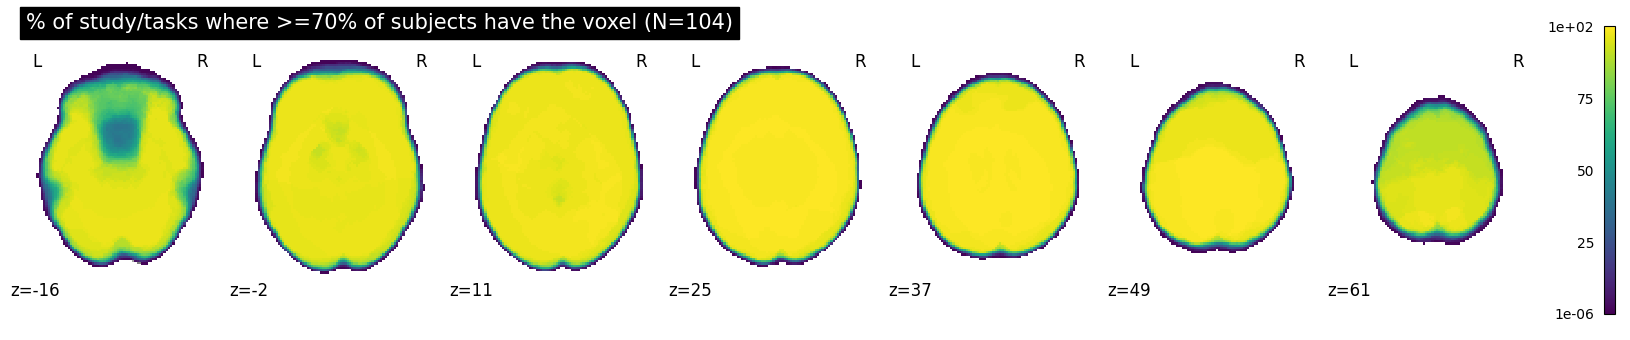

In [95]:
plotting.plot_stat_map(
    group_pct_path, display_mode="z", cut_coords=7,
    vmin=0, vmax=100, threshold=1e-6, cmap="viridis", colorbar=True,
    title=f"% of study/tasks where >={THRESH}% of subjects have the voxel "
          f"(N={len(pct_files)})",
)
